1.身份与环境记录

In [89]:
import os
import uuid
import hashlib
import platform
import numpy as np
import scipy
import matplotlib
import pandas as pd
# 修改为自己的学号
STUDENT_ID = 20244080228
CONDA_ENV = os.environ.get("CONDA_DEFAULT_ENV", "python 3.13.16")
print(f"[Conda 环境] {CONDA_ENV}")
MACHINE_FP = hashlib.sha256(
 f"{platform.node()}|{platform.machine()}|{platform.system()}|{uuid.getnode()}".encode()
).hexdigest()[:16]
RUN_ID = f"{STUDENT_ID}-{MACHINE_FP}"
print(f"[学号] {STUDENT_ID}")
print(f"[机器指纹] {MACHINE_FP}")
print(f"[RUN_ID] {RUN_ID}")

[Conda 环境] python 3.13.16
[学号] 20244080228
[机器指纹] 30b59092cf77f954
[RUN_ID] 20244080228-30b59092cf77f954


2.实验1：NumPy 数组、数据类型与索引

2.1分别创建整数、浮点数和布尔值 ndarray，输出每个数组的 dtype、shape 和
ndim。解释 NumPy 数组的数据类型与 Python 列表的差别。

In [90]:
int_arr = np.array([1, 2, 3, 4], dtype=int)
float_arr = np.array([1.2, 2.5, 3.8], dtype=float)
bool_arr = np.array([True, False, True, True], dtype=bool)

for name, arr in [("整数数组", int_arr), ("浮点数组", float_arr), ("布尔数组", bool_arr)]:
    print(f"{name}: {arr}")
    print(f"  dtype={arr.dtype}, shape={arr.shape}, ndim={arr.ndim}")

# 说明：
# NumPy ndarray 通常要求数组元素具有统一的数据类型，便于紧凑存储和向量化计算；
# Python list 可以混合存放不同类型的对象，但逐元素数值运算通常不如 NumPy 方便高效。

整数数组: [1 2 3 4]
  dtype=int64, shape=(4,), ndim=1
浮点数组: [1.2 2.5 3.8]
  dtype=float64, shape=(3,), ndim=1
布尔数组: [ True False  True  True]
  dtype=bool, shape=(4,), ndim=1


2.2 ⽤ np.arange(12) 创建⼀维数组，并分别变为形状 (3, 4) 和 (2, 3, 2) 的
数组。展⽰数组内容，说明改变形状时元素总数必须满⾜什么条件。

In [91]:
arr = np.arange(12)
arr_3x4 = arr.reshape(3, 4)
arr_2x3x2 = arr.reshape(2, 3, 2)

print("原一维数组：\n", arr)
print("\n形状 (3, 4)：\n", arr_3x4)
print("\n形状 (2, 3, 2)：\n", arr_2x3x2)
print("\n元素总数：", arr.size, arr_3x4.size, arr_2x3x2.size)

# reshape 前后元素总数必须相同；目标形状各维度乘积必须等于原数组元素数。

原一维数组：
 [ 0  1  2  3  4  5  6  7  8  9 10 11]

形状 (3, 4)：
 [[ 0  1  2  3]
 [ 4  5  6  7]
 [ 8  9 10 11]]

形状 (2, 3, 2)：
 [[[ 0  1]
  [ 2  3]
  [ 4  5]]

 [[ 6  7]
  [ 8  9]
  [10 11]]]

元素总数： 12 12 12


2.3 对形状为 (3, 4) 的数组完成以下索引：取第 2 ⾏、取第 1 ⾄第 3 列、取⼤于 6
的元素，并分别输出结果及其形状。

In [92]:
a = np.arange(12).reshape(3, 4)
print("原数组：\n", a)

row2 = a[1, :]       # 第 2 行（题目按从 1 开始计数）
cols1to3 = a[:, 0:3] # 第 1 至第 3 列
greater6 = a[a > 6]  # 所有大于 6 的元素

print("\n第 2 行：", row2, "shape =", row2.shape)
print("\n第 1 至第 3 列：\n", cols1to3, "shape =", cols1to3.shape)
print("\n大于 6 的元素：", greater6, "shape =", greater6.shape)

原数组：
 [[ 0  1  2  3]
 [ 4  5  6  7]
 [ 8  9 10 11]]

第 2 行： [4 5 6 7] shape = (4,)

第 1 至第 3 列：
 [[ 0  1  2]
 [ 4  5  6]
 [ 8  9 10]] shape = (3, 3)

大于 6 的元素： [ 7  8  9 10 11] shape = (5,)


2.4使⽤ np.arange(10) 分别选出“⼩于 2 或⼤于 7”和“⼤于 3 且⼩于 7”的元素。使
⽤括号配合 |、& 或 np.logical_or()、np.logical_and()。

In [93]:
a = np.arange(10)

less2_or_greater7 = a[(a < 2) | (a > 7)]
greater3_and_less7 = a[(a > 3) & (a < 7)]
# 等价写法示例：
same_or = a[np.logical_or(a < 2, a > 7)]
same_and = a[np.logical_and(a > 3, a < 7)]

print("小于 2 或大于 7：", less2_or_greater7)
print("大于 3 且小于 7：", greater3_and_less7)
print("logical_or 结果：", same_or)
print("logical_and 结果：", same_and)

# 使用 | 和 & 时，每个比较条件都要用括号括起来，不能用 Python 的 and/or 代替。

小于 2 或大于 7： [0 1 8 9]
大于 3 且小于 7： [4 5 6]
logical_or 结果： [0 1 8 9]
logical_and 结果： [4 5 6]


2.5 构造两个形状为 (2, 2) 的数组，对⽐ *、np.multiply() 与 @、
np.matmul() 的结果，说明逐元素乘法与矩阵乘法的区别。

In [94]:
A = np.array([[1, 2], [3, 4]])
B = np.array([[5, 6], [7, 8]])

print("A * B（逐元素乘法）：\n", A * B)
print("np.multiply(A, B)：\n", np.multiply(A, B))
print("A @ B（矩阵乘法）：\n", A @ B)
print("np.matmul(A, B)：\n", np.matmul(A, B))

# * 和 multiply 对应位置相乘；@ 和 matmul 执行矩阵乘法，即行与列做点积。

A * B（逐元素乘法）：
 [[ 5 12]
 [21 32]]
np.multiply(A, B)：
 [[ 5 12]
 [21 32]]
A @ B（矩阵乘法）：
 [[19 22]
 [43 50]]
np.matmul(A, B)：
 [[19 22]
 [43 50]]


3.实验2：随机抽样、统计与缺失值

3.1使⽤ np.random ⽣成 1,000 个均值为 70、标准差为 10 的模拟成绩；⽤np.clip
将数值限制在 0〜100 范围内。输出样本数、最⼩值、最⼤值、均值、标准差和极
差。

In [95]:
rng = np.random.default_rng(42)  # 固定种子，便于复现
scores = rng.normal(loc=70, scale=10, size=1000)
scores = np.clip(scores, 0, 100)

print("样本数：", scores.size)
print("最小值：", scores.min())
print("最大值：", scores.max())
print("均值：", scores.mean())
print("标准差（总体，ddof=0）：", scores.std())
print("极差：", np.ptp(scores))

样本数： 1000
最小值： 33.51587174785217
最大值： 100.0
均值： 69.70929595324685
标准差（总体，ddof=0）： 9.881580939490172
极差： 66.48412825214783


3.2从 np.arange(1, 11) 中不放回地抽取 5 个整数，⽐较均匀抽样与按整数⼤⼩成
⽐例加权抽样的写法。

In [96]:
population = np.arange(1, 11)
rng_sample = np.random.default_rng(123)

uniform_sample = rng_sample.choice(population, size=5, replace=False)
weights = population / population.sum()  # 数字越大，被抽中的相对权重越大
weighted_sample = rng_sample.choice(population, size=5, replace=False, p=weights)

print("总体：", population)
print("均匀不放回抽样：", uniform_sample)
print("按整数大小加权的不放回抽样：", weighted_sample)
print("权重：", weights)

# replace=False 表示不放回；p 中的概率之和必须为 1。

总体： [ 1  2  3  4  5  6  7  8  9 10]
均匀不放回抽样： [ 9  8  1 10  5]
按整数大小加权的不放回抽样： [ 9 10  6  7  4]
权重： [0.01818182 0.03636364 0.05454545 0.07272727 0.09090909 0.10909091
 0.12727273 0.14545455 0.16363636 0.18181818]


3.3 分别演⽰随机排列后保留原数组和原地打乱数组，打印操作前后的原数组以说明两
种⽅式的区别。

In [97]:
original = np.arange(10)
before = original.copy()

permuted = np.random.default_rng(7).permutation(original)  # 返回新数组
print("排列前原数组：", before)
print("permutation 返回的新数组：", permuted)
print("调用 permutation 后原数组：", original)

np.random.default_rng(7).shuffle(original)  # 原地打乱
print("shuffle 原地打乱后的原数组：", original)

排列前原数组： [0 1 2 3 4 5 6 7 8 9]
permutation 返回的新数组： [8 0 7 1 3 6 2 4 5 9]
调用 permutation 后原数组： [0 1 2 3 4 5 6 7 8 9]
shuffle 原地打乱后的原数组： [8 0 7 1 3 6 2 4 5 9]


3.4 将模拟成绩的第 10、20、30 个值设为 np.nan。⽐较普通均值和忽略缺失值后的
均值，统计缺失值个数，并说明 nan 对普通统计函数的影响

In [98]:
scores_with_nan = scores.copy()
scores_with_nan[[9, 19, 29]] = np.nan  # 第 10、20、30 个值（Python 索引从 0 开始）

print("普通均值：", np.mean(scores_with_nan))
print("忽略 NaN 的均值：", np.nanmean(scores_with_nan))
print("缺失值个数：", np.isnan(scores_with_nan).sum())
print("缺失值比例：", np.isnan(scores_with_nan).mean())

# np.mean 遇到 NaN 通常会返回 NaN；np.nanmean 会忽略 NaN 计算均值。

普通均值： nan
忽略 NaN 的均值： 69.71315691233939
缺失值个数： 3
缺失值比例： 0.003


3.5将含缺失值的模拟成绩及其序号整理成内存中的表格变量，供实验4直接使⽤；不
要写⼊磁盘。

In [99]:
scores_table = pd.DataFrame({
    "序号": np.arange(1, len(scores_with_nan) + 1),
    "成绩": scores_with_nan
})

display(scores_table.head(12))
print("表格形状：", scores_table.shape)
print("缺失值统计：")
display(scores_table.isna().sum())

# 此变量保留在当前 Notebook 内存中，不写入 CSV 或其他磁盘文件。
# 后续实验可直接使用 scores_table。

,序号,成绩
0,1,73.047171
1,2,59.600159
2,3,77.504512
3,4,79.405647
4,5,50.489648
5,6,56.978205
6,7,71.278404
7,8,66.837574
8,9,69.831988
9,10,NaN


表格形状： (1000, 2)
缺失值统计：


序号    0
成绩    3
dtype: int64

4.实验3：SciPy 数值计算与 Matplotlib 可视化

4.1使⽤ scipy.linalg.solve() 解线性⽅程组 、 ；⽤
NumPy 代⼊验证求得的解。

In [100]:
# 方程组：3x + y = 9；x + 2y = 8
A = np.array([[3, 1], [1, 2]], dtype=float)
b = np.array([9, 8], dtype=float)

solution = np.linalg.solve(A, b)
x, y = solution
print("求得解 [x, y]：", solution)
print("NumPy 代入验证 A @ solution：", A @ solution)
print("右侧 b：", b)
print("是否近似相等：", np.allclose(A @ solution, b))

求得解 [x, y]： [2. 3.]
NumPy 代入验证 A @ solution： [9. 8.]
右侧 b： [9. 8.]
是否近似相等： True


4.2 使⽤ scipy.optimize.root() 求⽅程 的正根和负根，分别给出初
始猜测值。打印求根是否成功以及结果，并检查函数值是否接近 0。

In [101]:
from scipy import optimize

def equation(x):
    return x**2 - 2

positive_result = optimize.root(equation, x0=1.0)
negative_result = optimize.root(equation, x0=-1.0)

for label, result in [("正根初始猜测 x0=1.0", positive_result),
                      ("负根初始猜测 x0=-1.0", negative_result)]:
    print(label)
    print("是否成功：", result.success)
    print("求根结果：", result.x)
    print("函数值：", equation(result.x))

正根初始猜测 x0=1.0
是否成功： True
求根结果： [1.41421356]
函数值： [-8.8817842e-16]
负根初始猜测 x0=-1.0
是否成功： True
求根结果： [-1.41421356]
函数值： [-8.8817842e-16]


4.3使⽤ scipy.optimize.minimize() 求 的最⼩值，报告
极⼩点和函数值，并与解析结果⽐较。

In [102]:
def f(x):
    return x[0]**2 + x[0] + 2

result = optimize.minimize(f, x0=np.array([0.0]))
x_min = result.x[0]
f_min = result.fun

print("优化是否成功：", result.success)
print("数值极小点：", x_min)
print("数值最小值：", f_min)
print("解析极小点：x = -1/2 =", -0.5)
print("解析最小值：f(-1/2) =", (-0.5)**2 + (-0.5) + 2)

# 配方：x²+x+2 = (x+1/2)² + 7/4，所以解析最小值为 1.75。

优化是否成功： True
数值极小点： -0.5000000064345924
数值最小值： 1.75
解析极小点：x = -1/2 = -0.5
解析最小值：f(-1/2) = 1.75


4.4 ⽣成两组独⽴的模拟样本：各 100 个观测值，第⼀组来⾃均值 0、标准差 1 的正态
分布，第⼆组来⾃均值 1、标准差 1 的正态分布。固定随机种⼦，使⽤
scipy.stats.ttest_ind() 进⾏独⽴样本 t 检验；报告 t 统计量、p 值及在
0.05 显著性⽔平下的判断。

In [103]:
from scipy import stats

rng_t = np.random.default_rng(2024)
sample1 = rng_t.normal(loc=0, scale=1, size=100)
sample2 = rng_t.normal(loc=1, scale=1, size=100)

test_result = stats.ttest_ind(sample1, sample2, equal_var=True)
print("第一组样本均值：", sample1.mean())
print("第二组样本均值：", sample2.mean())
print("t 统计量：", test_result.statistic)
print("p 值：", test_result.pvalue)
print("显著性水平：0.05")
if test_result.pvalue < 0.05:
    print("判断：拒绝两组总体均值相等的原假设，差异具有统计显著性。")
else:
    print("判断：未能拒绝两组总体均值相等的原假设，差异不具有统计显著性。")

第一组样本均值： 0.07895568863581767
第二组样本均值： 0.8562778315340099
t 统计量： -5.566546811591021
p 值： 8.378085154202517e-08
显著性水平：0.05
判断：拒绝两组总体均值相等的原假设，差异具有统计显著性。


4.5⽤ Matplotlib 为实验2的有效成绩画直⽅图，并另画箱线图；为函数 、
、 在 上画同⼀坐标系的折线图。每张图包含标题、坐标轴
标签，折线图包含图例。直接在 Notebook 中显⽰图像，不保存为⽂件。

C:\Users\YJX\AppData\Local\Temp\ipykernel_38616\1518179224.py:10: UserWarning: Glyph 25104 (\N{CJK UNIFIED IDEOGRAPH-6210}) missing from font(s) DejaVu Sans.
  plt.tight_layout()
C:\Users\YJX\AppData\Local\Temp\ipykernel_38616\1518179224.py:10: UserWarning: Glyph 32489 (\N{CJK UNIFIED IDEOGRAPH-7EE9}) missing from font(s) DejaVu Sans.
  plt.tight_layout()
C:\Users\YJX\AppData\Local\Temp\ipykernel_38616\1518179224.py:10: UserWarning: Glyph 39057 (\N{CJK UNIFIED IDEOGRAPH-9891}) missing from font(s) DejaVu Sans.
  plt.tight_layout()
C:\Users\YJX\AppData\Local\Temp\ipykernel_38616\1518179224.py:10: UserWarning: Glyph 25968 (\N{CJK UNIFIED IDEOGRAPH-6570}) missing from font(s) DejaVu Sans.
  plt.tight_layout()
C:\Users\YJX\AppData\Local\Temp\ipykernel_38616\1518179224.py:10: UserWarning: Glyph 27169 (\N{CJK UNIFIED IDEOGRAPH-6A21}) missing from font(s) DejaVu Sans.
  plt.tight_layout()
C:\Users\YJX\AppData\Local\Temp\ipykernel_38616\1518179224.py:10: UserWarning: Glyph 25311 (\N{CJK UNIFIE

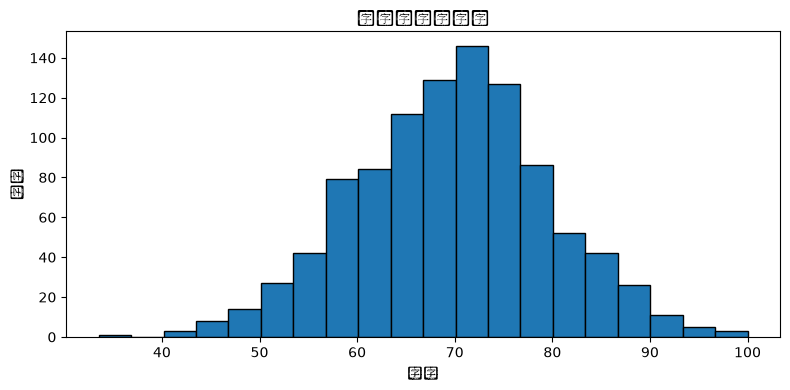

C:\Users\YJX\AppData\Local\Temp\ipykernel_38616\1518179224.py:14: MatplotlibDeprecationWarning: vert: bool was deprecated in Matplotlib 3.11 and will be removed in 3.13. Use orientation: {'vertical', 'horizontal'} instead.
  plt.boxplot(valid_scores, vert=True)
C:\Users\YJX\AppData\Local\Temp\ipykernel_38616\1518179224.py:17: UserWarning: Glyph 25104 (\N{CJK UNIFIED IDEOGRAPH-6210}) missing from font(s) DejaVu Sans.
  plt.tight_layout()
C:\Users\YJX\AppData\Local\Temp\ipykernel_38616\1518179224.py:17: UserWarning: Glyph 32489 (\N{CJK UNIFIED IDEOGRAPH-7EE9}) missing from font(s) DejaVu Sans.
  plt.tight_layout()
C:\Users\YJX\AppData\Local\Temp\ipykernel_38616\1518179224.py:17: UserWarning: Glyph 27169 (\N{CJK UNIFIED IDEOGRAPH-6A21}) missing from font(s) DejaVu Sans.
  plt.tight_layout()
C:\Users\YJX\AppData\Local\Temp\ipykernel_38616\1518179224.py:17: UserWarning: Glyph 25311 (\N{CJK UNIFIED IDEOGRAPH-62DF}) missing from font(s) DejaVu Sans.
  plt.tight_layout()
C:\Users\YJX\AppData\L

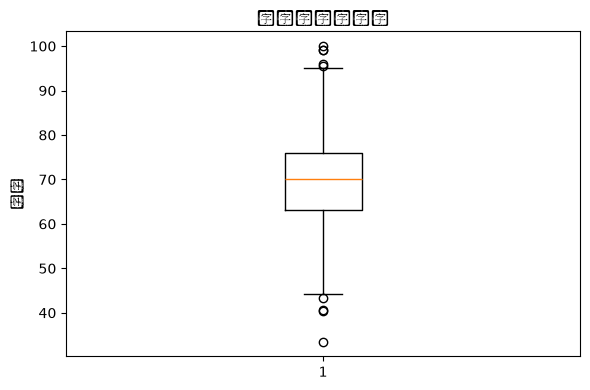

In [104]:
import matplotlib.pyplot as plt

valid_scores = scores_table["成绩"].dropna()

plt.figure(figsize=(8, 4))
plt.hist(valid_scores, bins=20, edgecolor="black")
plt.title("模拟成绩直方图")
plt.xlabel("成绩")
plt.ylabel("频数")
plt.tight_layout()
plt.show()

plt.figure(figsize=(6, 4))
plt.boxplot(valid_scores, vert=True)
plt.title("模拟成绩箱线图")
plt.ylabel("成绩")
plt.tight_layout()
plt.show()

C:\Users\YJX\AppData\Local\Temp\ipykernel_38616\3158157166.py:12: UserWarning: Glyph 20989 (\N{CJK UNIFIED IDEOGRAPH-51FD}) missing from font(s) DejaVu Sans.
  plt.tight_layout()
C:\Users\YJX\AppData\Local\Temp\ipykernel_38616\3158157166.py:12: UserWarning: Glyph 25968 (\N{CJK UNIFIED IDEOGRAPH-6570}) missing from font(s) DejaVu Sans.
  plt.tight_layout()
C:\Users\YJX\AppData\Local\Temp\ipykernel_38616\3158157166.py:12: UserWarning: Glyph 12289 (\N{IDEOGRAPHIC COMMA}) missing from font(s) DejaVu Sans.
  plt.tight_layout()
C:\Users\YJX\AppData\Roaming\Python\Python313\site-packages\IPython\core\pylabtools.py:170: UserWarning: Glyph 20989 (\N{CJK UNIFIED IDEOGRAPH-51FD}) missing from font(s) DejaVu Sans.
  fig.canvas.print_figure(bytes_io, **kw)
C:\Users\YJX\AppData\Roaming\Python\Python313\site-packages\IPython\core\pylabtools.py:170: UserWarning: Glyph 25968 (\N{CJK UNIFIED IDEOGRAPH-6570}) missing from font(s) DejaVu Sans.
  fig.canvas.print_figure(bytes_io, **kw)
C:\Users\YJX\AppData

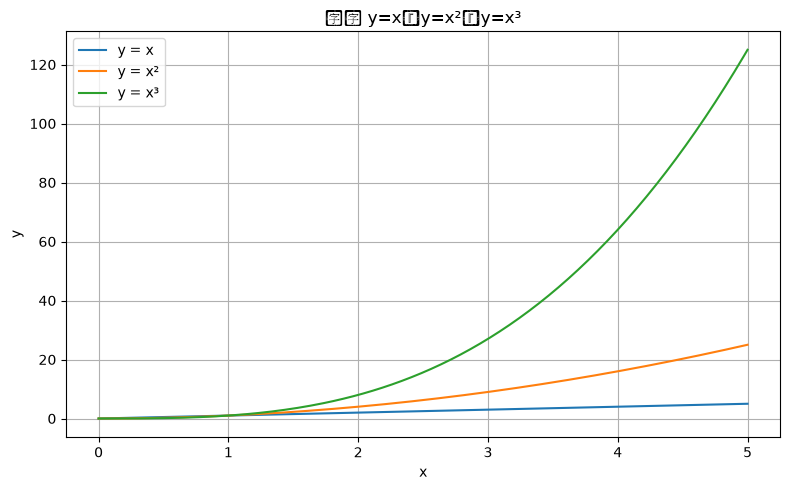

In [105]:
x_values = np.linspace(0, 5, 200)

plt.figure(figsize=(8, 5))
plt.plot(x_values, x_values, label="y = x")
plt.plot(x_values, x_values**2, label="y = x²")
plt.plot(x_values, x_values**3, label="y = x³")
plt.title("函数 y=x、y=x²、y=x³")
plt.xlabel("x")
plt.ylabel("y")
plt.legend()
plt.grid(True)
plt.tight_layout()
plt.show()

5.实验4：pandas Series、DataFrame 与内存中的
CSV 读写

5.1使⽤以下模拟数据创建 DataFrame，⾏索引为姓名；计算 Total（三科总分）和
Average（三科平均分）两列。输出⾏索引、列名、前 3 ⾏和基本统计信息。

In [106]:
records = {
    "Name": ["Alice", "Bob", "Carol", "David", "Eva", "Frank"],
    "Group": ["A", "A", "B", "B", "A", "B"],
    "Math": [88, 72, 91, 65, 79, 84],
    "English": [90, 68, 85, 73, 92, 77],
    "Python": [95, 80, 89, 70, 86, 82],
}

df = pd.DataFrame(records).set_index("Name")
subject_cols = ["Math", "English", "Python"]
df["Total"] = df[subject_cols].sum(axis=1)
df["Average"] = df[subject_cols].mean(axis=1)

print("行索引：", df.index.tolist())
print("列名：", df.columns.tolist())
print("\n前 3 行：")
display(df.head(3))
print("\n基本统计信息：")
display(df.describe())

行索引： ['Alice', 'Bob', 'Carol', 'David', 'Eva', 'Frank']
列名： ['Group', 'Math', 'English', 'Python', 'Total', 'Average']

前 3 行：


,Group,Math,English,Python,Total,Average
Name,,,,,,
Alice,A,88,90,95,273,91.000000
Bob,A,72,68,80,220,73.333333
Carol,B,91,85,89,265,88.333333



基本统计信息：


,Math,English,Python,Total,Average
count,6.000000,6.000000,6.000000,6.000000,6.000000
mean,79.833333,80.833333,83.666667,244.333333,81.444444
std,9.907909,9.662643,8.547904,25.781130,8.593710
min,65.000000,68.000000,70.000000,208.000000,69.333333
25%,73.750000,74.000000,80.500000,225.750000,75.250000
50%,81.500000,81.000000,84.000000,250.000000,83.333333
75%,87.000000,88.750000,88.250000,263.000000,87.666667
max,91.000000,92.000000,95.000000,273.000000,91.000000


5.2 分别⽤ loc 和 iloc 读取 Carol 的记录，并筛选平均分不低于 80 的学⽣。

In [107]:
print("loc 读取 Carol：")
display(df.loc["Carol"])

print("iloc 读取 Carol（Carol 当前是第 3 行，位置索引为 2）：")
display(df.iloc[2])

print("平均分不低于 80 的学生：")
display(df.loc[df["Average"] >= 80])

loc 读取 Carol：


Group              B
Math              91
English           85
Python            89
Total            265
Average    88.333333
Name: Carol, dtype: object

iloc 读取 Carol（Carol 当前是第 3 行，位置索引为 2）：


Group              B
Math              91
English           85
Python            89
Total            265
Average    88.333333
Name: Carol, dtype: object

平均分不低于 80 的学生：


,Group,Math,English,Python,Total,Average
Name,,,,,,
Alice,A,88,90,95,273,91.000000
Carol,B,91,85,89,265,88.333333
Eva,A,79,92,86,257,85.666667
Frank,B,84,77,82,243,81.000000


5.3 分别⽤ mean(axis=0) 和 mean(axis=1) 计算三科成绩的列均值和每名学⽣的
⾏均值。

In [108]:
print("三科列均值（axis=0）：")
display(df[subject_cols].mean(axis=0))

print("每名学生的行均值（axis=1）：")
display(df[subject_cols].mean(axis=1))

# axis=0 沿行方向汇总，得到每一列的均值；axis=1 沿列方向汇总，得到每一行的均值。

三科列均值（axis=0）：


Math       79.833333
English    80.833333
Python     83.666667
dtype: float64

每名学生的行均值（axis=1）：


Name
Alice    91.000000
Bob      73.333333
Carol    88.333333
David    69.333333
Eva      85.666667
Frank    81.000000
dtype: float64

5.4 使⽤ apply() 计算每名学⽣的三科最⾼分，使⽤ agg() ⼀次得到每科的最⼩值、
均值和最⼤值。任选⼀列使⽤ rank() 给学⽣排名。

In [109]:
df["最高分"] = df[subject_cols].apply(max, axis=1)
print("每名学生的三科最高分：")
display(df[["最高分"]])

print("每科最小值、均值、最大值：")
display(df[subject_cols].agg(["min", "mean", "max"]))

df["Math排名"] = df["Math"].rank(ascending=False, method="min")
print("按数学成绩排名（1 表示最高分）：")
display(df[["Math", "Math排名"]].sort_values("Math排名"))

每名学生的三科最高分：


,最高分
Name,
Alice,95
Bob,80
Carol,91
David,73
Eva,92
Frank,84


每科最小值、均值、最大值：


,Math,English,Python
min,65.000000,68.000000,70.000000
mean,79.833333,80.833333,83.666667
max,91.000000,92.000000,95.000000


按数学成绩排名（1 表示最高分）：


,Math,Math排名
Name,,
Carol,91,1.0
Alice,88,2.0
Frank,84,3.0
Eva,79,4.0
Bob,72,5.0
David,65,6.0


5.5按 Group 分组，统计每组⼈数和三科平均分。再⽤ transform('mean') 为每⾏
增加其所在组的 Python 平均分。

In [110]:
group_summary = df.groupby("Group").agg(
    人数=("Group", "size"),
    Math平均分=("Math", "mean"),
    English平均分=("English", "mean"),
    Python平均分=("Python", "mean"),
)
print("各组人数和三科平均分：")
display(group_summary)

df["组内Python平均分"] = df.groupby("Group")["Python"].transform("mean")
print("每名学生增加其所在组的 Python 平均分：")
display(df[["Group", "Python", "组内Python平均分"]])

各组人数和三科平均分：


,人数,Math平均分,English平均分,Python平均分
Group,,,,
A,3,79.666667,83.333333,87.000000
B,3,80.000000,78.333333,80.333333


每名学生增加其所在组的 Python 平均分：


,Group,Python,组内Python平均分
Name,,,
Alice,A,95,87.000000
Bob,A,80,87.000000
Carol,B,89,80.333333
David,B,70,80.333333
Eva,A,86,87.000000
Frank,B,82,80.333333


5.6 ⽤ filter() 保留 Python 平均分不低于 80 的组；输出保留的组和学⽣。

In [111]:
# filter 的条件作用于每个分组；保留组内 Python 平均分 >= 80 的整个组。
kept_groups = df.groupby("Group").filter(lambda group: group["Python"].mean() >= 80)

print("保留的组：", kept_groups["Group"].drop_duplicates().tolist())
print("保留的学生：")
display(kept_groups)

保留的组： ['A', 'B']
保留的学生：


,Group,Math,English,Python,Total,Average,最高分,Math排名,组内Python平均分
Name,,,,,,,,,
Alice,A,88,90,95,273,91.000000,95,2.0,87.000000
Bob,A,72,68,80,220,73.333333,80,5.0,87.000000
Carol,B,91,85,89,265,88.333333,91,1.0,80.333333
David,B,65,73,70,208,69.333333,73,6.0,80.333333
Eva,A,79,92,86,257,85.666667,92,4.0,87.000000
Frank,B,84,77,82,243,81.000000,84,3.0,80.333333


5.7计算三科成绩之间的协⽅差矩阵和⽪尔森相关系数矩阵；选择其中⼀对科⽬，解释
协⽅差符号与相关系数⼤⼩的含义。

In [112]:
cov_matrix = df[subject_cols].cov()
corr_matrix = df[subject_cols].corr(method="pearson")

print("协方差矩阵：")
display(cov_matrix)
print("Pearson 相关系数矩阵：")
display(corr_matrix)

# 解释示例：查看 Math 与 Python。
cov_math_python = cov_matrix.loc["Math", "Python"]
corr_math_python = corr_matrix.loc["Math", "Python"]
print(f"Math 与 Python 的协方差：{cov_math_python:.3f}")
print(f"Math 与 Python 的 Pearson 相关系数：{corr_math_python:.3f}")
print("协方差为正表示两科成绩倾向于同向变化；相关系数越接近 1，线性正相关越强，"
      "越接近 -1，线性负相关越强，接近 0 表示线性相关较弱。")

协方差矩阵：


,Math,English,Python
Math,98.166667,62.566667,74.933333
English,62.566667,93.366667,62.533333
Python,74.933333,62.533333,73.066667


Pearson 相关系数矩阵：


,Math,English,Python
Math,1.000000,0.653529,0.884776
English,0.653529,1.000000,0.757105
Python,0.884776,0.757105,1.000000


Math 与 Python 的协方差：74.933
Math 与 Python 的 Pearson 相关系数：0.885
协方差为正表示两科成绩倾向于同向变化；相关系数越接近 1，线性正相关越强，越接近 -1，线性负相关越强，接近 0 表示线性相关较弱。
